# Community experiment setup -- inspection

Reads `outputs/` (written by `run_setup.py`) and plots it. Nothing here writes a file:
the design is changed in `setup_config.yaml` and rebuilt with `python run_setup.py --force`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
OUT = Path("outputs")
comm = pd.read_csv(OUT / "communities.csv")
lay = pd.read_csv(OUT / "layout.csv")
pool = pd.read_csv(OUT / "pool.csv")
tr = pd.read_csv(OUT / "strain_transfers.csv")
# validated categorical slots 1-2 (blue, orange); recessive ink and grid
C = {"core": "#2a78d6", "extended": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 9})
print(open(OUT / "summary.txt").read())
print(open(OUT / "validation.txt").read())

experiment 20261021  seed 20261021
pool: 133 genomes (75 core, 58 extended)

main: 408 communities x 3 = 1224 wells
  by module: {'small': 340, 'mid': 16, 'trio_pair': 15, 'leave_out': 9, 'large_test': 9, 'sanity_pair': 8, 'resolution_test': 6, 'trio': 5}
  by size:   {2: 23, 3: 48, 4: 43, 5: 49, 6: 43, 7: 50, 8: 43, 9: 42, 10: 42, 12: 4, 14: 3, 15: 1, 16: 3, 18: 3, 20: 4, 25: 1, 30: 1, 40: 1, 51: 1, 55: 1, 61: 1, 66: 1}
  core / extended: 285 / 123
  MPD (bp) 5/50/95%: [48.0, 231.0, 309.0]

passage: 102 communities x 3 = 306 wells
  by module: {'small': 95, 'large_test': 7}
  by size:   {3: 12, 4: 12, 5: 12, 6: 12, 7: 12, 8: 12, 9: 12, 10: 11, 15: 1, 20: 1, 25: 1, 30: 1, 40: 1, 51: 1, 61: 1}
  core / extended: 102 / 0
  MPD (bp) 5/50/95%: [85.0, 215.0, 317.0]
  main-plate wells, trio              15 (1.2%)
  main-plate wells, trio_pair         45 (3.7%)
  main-plate wells, sanity_pair       24 (2.0%)
  main-plate wells, leave_out         27 (2.2%)
  main-plate wells, mid              

## Size x relatedness coverage

Each dot is one community of up to 10 members (larger ones are listed below).
Relatedness is the mean pairwise 16S distance between members: low = one clade, high =
across phyla. Each size is filled in three relatedness terciles, so every size spans the
range it can reach.

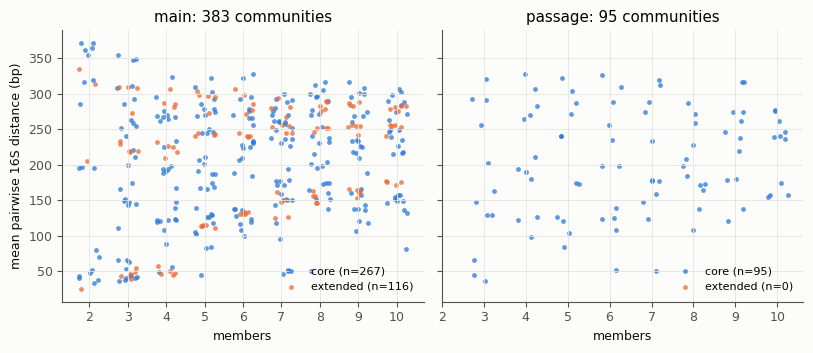

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
rng = np.random.default_rng(0)
axes[2].remove()
for ax, blk in zip(axes, ["main", "passage"]):
    c = comm[comm.blocks.str.contains(blk) & (comm["size"] <= 10)]
    for p in ["core", "extended"]:
        s = c[c.pool == p]
        ax.scatter(s["size"] + rng.uniform(-0.28, 0.28, len(s)), s.mpd_bp, s=12, color=C[p],
                   alpha=0.75, linewidths=0, label=f"{p} (n={len(s)})")
    ax.set(title=f"{blk}: {c.shape[0]} communities", xlabel="members", xticks=range(2, 11))
    ax.legend(frameon=False, loc="lower right", fontsize=8)
axes[0].set_ylabel("mean pairwise 16S distance (bp)")
fig.tight_layout()

In [3]:
cols = ["community_id", "size", "pool", "blocks", "target_min_sep", "min_sep_bp", "mpd_bp", "member_nL", "inoculum_uL"]
print("large tests:")
display(comm[comm.module == "large_test"][cols].round(2))
print("12-20 member communities:")
display(comm[comm.module == "mid"][["community_id", "size", "pool", "mpd_bp"]].round(0))
print("resolution tests (one deliberately close pair):")
display(comm[comm.module == "resolution_test"][["community_id", "members", "close_pair", "close_pair_bp", "min_sep_bp"]])
print("trios and their pairs:")
display(comm[comm.module.isin(["trio", "trio_pair"])][["community_id", "module", "members", "parent", "pairs_measured_20260907", "mpd_bp"]].round(0))
print("sanity pairs (re-measured from 20260907):")
display(comm[comm.module == "sanity_pair"][["community_id", "members", "min_sep_bp"]])
print("leave-out series:")
display(comm[comm.module == "leave_out"][["community_id", "size", "removed"]])

large tests:


,community_id,size,pool,blocks,target_min_sep,min_sep_bp,mpd_bp,member_nL,inoculum_uL
43,K0044,15,core,main;passage,30.0,30.0,306.89,100,1.50
44,K0045,20,core,main;passage,30.0,41.0,276.61,100,2.00
45,K0046,25,core,main;passage,30.0,32.0,299.44,100,2.50
46,K0047,30,core,main;passage,30.0,30.0,296.75,100,3.00
47,K0048,40,core,main;passage,30.0,30.0,284.64,100,4.00
48,K0049,51,core,main;passage,30.0,30.0,289.66,75,3.82
49,K0050,55,extended,main,30.0,30.0,291.62,75,4.12
50,K0051,61,core,main;passage,15.0,15.0,279.62,75,4.58
51,K0052,66,extended,main,15.0,15.0,280.78,75,4.95


12-20 member communities:


,community_id,size,pool,mpd_bp
52,K0053,12,core,238.0
53,K0054,14,core,210.0
54,K0055,16,core,278.0
55,K0056,18,core,286.0
56,K0057,20,core,245.0
57,K0058,12,core,242.0
58,K0059,14,core,255.0
59,K0060,16,core,243.0
60,K0061,18,core,257.0
61,K0062,20,core,290.0


resolution tests (one deliberately close pair):


...

,community_id,module,members,parent,pairs_measured_20260907,mpd_bp
8,K0009,trio,B20 B4 O17,NaN,1,40.0
9,K0010,trio_pair,B20 B4,K0009,0,37.0
10,K0011,trio_pair,B20 O17,K0009,0,51.0
11,K0012,trio_pair,B4 O17,K0009,1,33.0
12,K0013,trio,K8 L24 P6,NaN,1,63.0
13,K0014,trio_pair,K8 L24,K0013,0,70.0
14,K0015,trio_pair,L24 P6,K0013,0,80.0
15,K0016,trio_pair,K8 P6,K0013,1,40.0
16,K0017,trio,J5 L2 O6,NaN,1,145.0
17,K0018,trio_pair,J5 L2,K0017,0,43.0


sanity pairs (re-measured from 20260907):


,community_id,members,min_sep_bp
0,K0001,F15 G8,24.0
1,K0002,A24 O18,365.0
2,K0003,J4 K16,205.0
3,K0004,J12 K6,316.0
4,K0005,D16 F14,285.0
5,K0006,C1 D12,335.0
6,K0007,O19 P11,195.0
7,K0008,G7 O13,314.0


leave-out series:


,community_id,size,removed
28,K0029,8,NaN
29,K0030,7,M19
30,K0031,7,F2
31,K0032,7,L15
32,K0033,7,F6
33,K0034,7,C17
34,K0035,7,A11
35,K0036,7,N15
36,K0037,7,L4


## Strain usage

Wells containing each strain on the main (sequenced 24 h) plates. Extended strains appear
less often by construction: they are confined to the extended third of the communities.

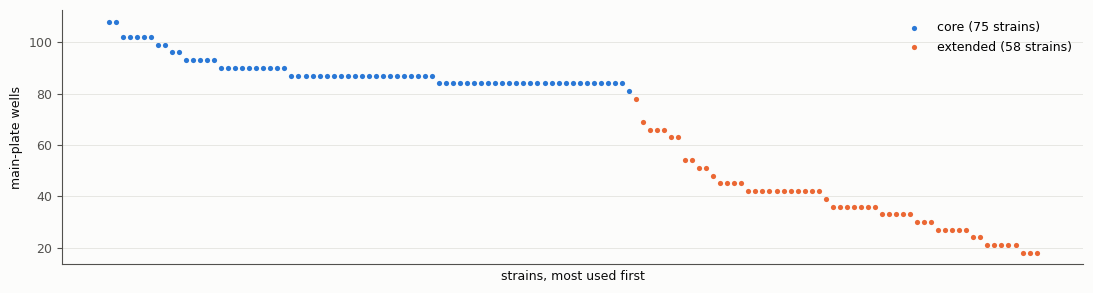

In [4]:
m = lay[(lay.block == "main") & (lay.well_type == "community")]
inc = pd.Series([x for r in m.members for x in r.split()]).value_counts()
pp = pool.set_index("strain")["pool"]
fig, ax = plt.subplots(figsize=(11, 3))
for p in ["core", "extended"]:
    s = inc[inc.index.map(pp) == p]
    x = [list(inc.index).index(k) for k in s.index]
    ax.scatter(x, s.values, s=14, color=C[p], linewidths=0, label=f"{p} ({len(s)} strains)")
ax.set(xlabel="strains, most used first", ylabel="main-plate wells", xticks=[])
ax.legend(frameon=False)
fig.tight_layout()

## Plate maps

Community size per well on every inoculated plate (blank-medium wells marked B).
Replicates of a community sit on different plates, except on the passage plate (5), where
all three are on the plate but never in the same row or next to each other.

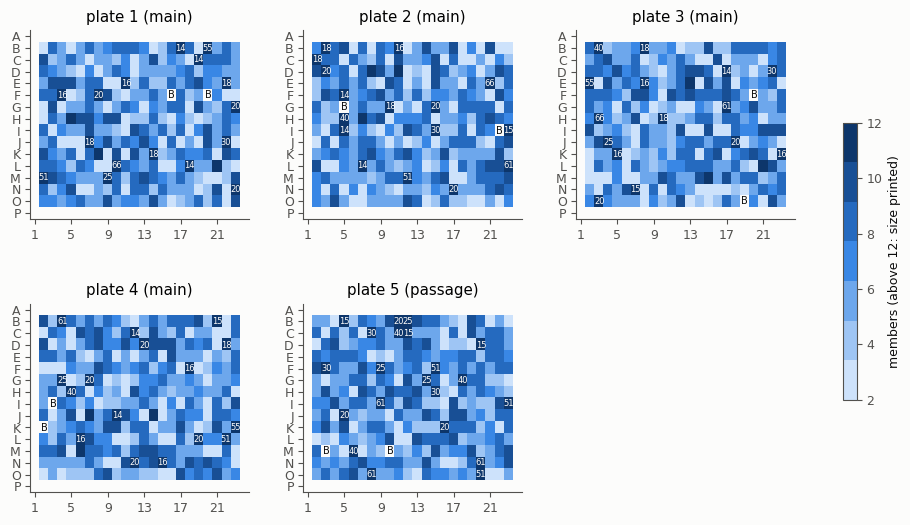

In [5]:
plates_ = sorted(lay[lay.inoculated].plate.unique())
ROWS = "ABCDEFGHIJKLMNOP"
cmap = ListedColormap(["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
axes.flat[-1].remove()
for ax, p in zip(axes.flat, plates_):
    g = lay[lay.plate == p]
    M = np.full((16, 24), np.nan)
    for r in g.itertuples():
        M[ROWS.index(r.well[0]), int(r.well[1:]) - 1] = min(r.size, 12) if r.well_type == "community" else np.nan
    im = ax.imshow(M, cmap=cmap, vmin=2, vmax=12, aspect="auto")
    for r in g[g.well_type == "blank"].itertuples():
        ax.text(int(r.well[1:]) - 1, ROWS.index(r.well[0]), "B", ha="center", va="center", fontsize=7, color=INK)
    big = g[g["size"] > 12]
    for r in big.itertuples():
        ax.text(int(r.well[1:]) - 1, ROWS.index(r.well[0]), str(r.size), ha="center", va="center", fontsize=6, color="#fcfcfb")
    blk = g.block.iloc[0]
    ax.set(title=f"plate {p} ({blk})", xticks=range(0, 24, 4), xticklabels=range(1, 25, 4),
           yticks=range(16), yticklabels=list(ROWS))
    ax.grid(False)
fig.subplots_adjust(hspace=0.45, wspace=0.25, right=0.86)
cb = fig.colorbar(im, ax=list(axes.flat[:len(plates_)]), shrink=0.6, label="members (above 12: size printed)")
plt.show()

## Inoculum

Equal volume per member (100 nL; 75 nL in communities above 50 members, so no well gets
more than 5 uL = 10% of the culture). Left: preculture carried into each well. Right:
volume drawn from each source well over the whole run -- all under the 25 uL that a fill
allows, so no refill.

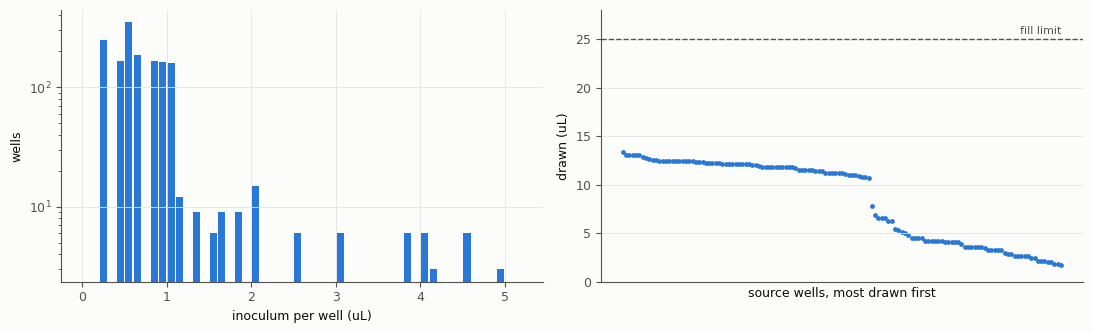

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
w = tr.groupby(["dest_plate", "dest_well"]).volume_nL.sum() / 1000
ax[0].hist(w, bins=np.linspace(0, 5.2, 53), color=C["core"], rwidth=0.85)
ax[0].set(xlabel="inoculum per well (uL)", ylabel="wells", yscale="log")
d = (tr.groupby("strain").volume_nL.sum() / 1000).sort_values(ascending=False)
ax[1].scatter(range(len(d)), d.values, s=12, color=C["core"], linewidths=0)
ax[1].axhline(25, color=MUTED, lw=1, ls="--"); ax[1].text(len(d) - 1, 25.5, "fill limit", color=MUTED, fontsize=8, ha="right")
ax[1].set(xlabel="source wells, most drawn first", ylabel="drawn (uL)", ylim=(0, 28), xticks=[])
fig.tight_layout()